In [1]:
import pandas as pd

df = pd.DataFrame({
    "Age": [20, 21, 19, 22, 20],
    "Gender": ["Male", "Female", "Male", "Female", "Male"],
    "Study_Hours": [4.0, 2.0, 6.0, 3.0, 1.0],
    "Marks": [75, 48, 90, 60, 35],
    "Passed": ["Yes", "No", "Yes", "Yes", "No"]
})

print(df.dtypes)

Age              int64
Gender             str
Study_Hours    float64
Marks            int64
Passed             str
dtype: object


In [10]:
numerical_columns = df.select_dtypes(
    include="number"
).columns

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

print("Numerical:", list(numerical_columns))
print("Categorical:", list(categorical_columns))

Numerical: ['Age', 'Study_Hours', 'Marks']
Categorical: ['Gender', 'Passed']


C:\Users\Tejas Gaikwad\AppData\Local\Temp\ipykernel_25476\1538566734.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [1]:
import pandas as pd
data = {
    "Name": ["Amit", "Priya", "Rahul", "Sneha"],
    "Age": ["21", "22", "twenty", "23"],
    "Salary": ["30000", "45000", "50000", "unknown"],
    "Joining_Date": [
        "2025-01-10",
        "2025-02-15",
        "invalid",
        "2025-04-20"
    ]
}

df = pd.DataFrame(data)

print(df)
print(df.dtypes)

    Name     Age   Salary Joining_Date
0   Amit      21    30000   2025-01-10
1  Priya      22    45000   2025-02-15
2  Rahul  twenty    50000      invalid
3  Sneha      23  unknown   2025-04-20
Name            str
Age             str
Salary          str
Joining_Date    str
dtype: object


In [2]:
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")#convert the value into numeric values - IF VALUES ARE NOT VALID GIVES NaN
print(df["Age"])

0    21.0
1    22.0
2     NaN
3    23.0
Name: Age, dtype: float64


In [3]:
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")

print(df["Salary"])

0    30000.0
1    45000.0
2    50000.0
3        NaN
Name: Salary, dtype: float64


In [4]:
print(df["Salary"].isnull().sum())

1


In [5]:
df["Joining_Date"] = pd.to_datetime(df["Joining_Date"],errors="coerce")
df["Joining_Date"]

0   2025-01-10
1   2025-02-15
2          NaT
3   2025-04-20
Name: Joining_Date, dtype: datetime64[us]

In [6]:
df

,Name,Age,Salary,Joining_Date
0,Amit,21.0,30000.0,2025-01-10
1,Priya,22.0,45000.0,2025-02-15
2,Rahul,NaN,50000.0,NaT
3,Sneha,23.0,NaN,2025-04-20


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Name          4 non-null      str           
 1   Age           3 non-null      float64       
 2   Salary        3 non-null      float64       
 3   Joining_Date  3 non-null      datetime64[us]
dtypes: datetime64[us](1), float64(2), str(1)
memory usage: 279.0 bytes


In [8]:
df.describe()

,Age,Salary,Joining_Date
count,3.0,3.000000,3
mean,22.0,41666.666667,2025-02-24 08:00:00
min,21.0,30000.000000,2025-01-10 00:00:00
25%,21.5,37500.000000,2025-01-28 00:00:00
50%,22.0,45000.000000,2025-02-15 00:00:00
75%,22.5,47500.000000,2025-03-19 00:00:00
max,23.0,50000.000000,2025-04-20 00:00:00
std,1.0,10408.329997,NaN


In [16]:
print(df.mean(numeric_only=True))
print(df.median(numeric_only = True))
print(df.mode(numeric_only = True))

Age          22.000000
Salary    41666.666667
dtype: float64
Age          22.0
Salary    45000.0
dtype: float64
    Age   Salary
0  21.0  30000.0
1  22.0  45000.0
2  23.0  50000.0


In [15]:
print("mode", df["Salary"].mode())
print("mean",df["Salary"].mean())
print("median",df["Salary"].median())

mode 0    30000.0
1    45000.0
2    50000.0
Name: Salary, dtype: float64
mean 41666.666666666664
median 45000.0


In [17]:
df["Salary"].std()

np.float64(10408.329997330664)

In [18]:
df["Salary"].var()

np.float64(108333333.33333333)

In [23]:
df["Department"] = ["IT", "Sales", "HR", "IT"]

print(df["Department"].value_counts())

Department
IT       2
Sales    1
HR       1
Name: count, dtype: int64


In [24]:
print(df["Department"].mode())

0    IT
Name: Department, dtype: str


In [25]:
print(df["Department"].describe())

count      4
unique     3
top       IT
freq       2
Name: Department, dtype: object


In [1]:
import pandas as pd

data = {
    "Name": ["Amit", "Priya", "Rahul", "Sneha", "Karan"],
    "Age": [21, None, 24, 23, None],
    "Salary": [30000, 40000, None, 45000, 35000],
    "Department": ["IT", "HR", "IT", None, "IT"]
}

df = pd.DataFrame(data)

print(df)

    Name   Age   Salary Department
0   Amit  21.0  30000.0         IT
1  Priya   NaN  40000.0         HR
2  Rahul  24.0      NaN         IT
3  Sneha  23.0  45000.0        NaN
4  Karan   NaN  35000.0         IT


In [2]:
df.isna().sum()

Name          0
Age           2
Salary        1
Department    1
dtype: int64

In [3]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [4]:
df["Salary"] = df["Salary"].fillna(df["Salary"].median())
df["Department"] = df["Department"].fillna(df["Department"].mode()[0])#it has values and freq so we take index

In [5]:
df

,Name,Age,Salary,Department
0,Amit,21.0,30000.0,IT
1,Priya,23.0,40000.0,HR
2,Rahul,24.0,37500.0,IT
3,Sneha,23.0,45000.0,IT
4,Karan,23.0,35000.0,IT


In [6]:
import pandas as pd

data = {
    "Name": ["Rahul", "Priya", "Rahul", "Amit", "Priya"],
    "Department": ["IT", "HR", "IT", "Sales", "HR"],
    "Salary": [40000, 35000, 40000, 30000, 35000]
}

df = pd.DataFrame(data)

print(df)

    Name Department  Salary
0  Rahul         IT   40000
1  Priya         HR   35000
2  Rahul         IT   40000
3   Amit      Sales   30000
4  Priya         HR   35000


In [7]:
#duplicate elements - checking
df.duplicated()

0    False
1    False
2     True
3    False
4     True
dtype: bool

In [8]:
#check which elemnts are duplicates
df[df.duplicated()]

,Name,Department,Salary
2,Rahul,IT,40000
4,Priya,HR,35000


In [10]:
#drop the duplicates _ return only remaining elements
df.drop_duplicates()


,Name,Department,Salary
0,Rahul,IT,40000
1,Priya,HR,35000
3,Amit,Sales,30000


In [11]:
df

,Name,Department,Salary
0,Rahul,IT,40000
1,Priya,HR,35000
2,Rahul,IT,40000
3,Amit,Sales,30000
4,Priya,HR,35000


In [12]:
df.drop_duplicates(keep = "last")

,Name,Department,Salary
2,Rahul,IT,40000
3,Amit,Sales,30000
4,Priya,HR,35000


In [13]:
df.drop_duplicates(keep = "first")

,Name,Department,Salary
0,Rahul,IT,40000
1,Priya,HR,35000
3,Amit,Sales,30000


In [14]:
data = {
    "Employee_ID": [101, 102, 101, 103],
    "Name": ["Rahul", "Priya", "Rahul", "Amit"],
    "Salary": [40000, 35000, 45000, 30000]
}

df = pd.DataFrame(data)

print(df.duplicated(subset=["Employee_ID"]))

0    False
1    False
2     True
3    False
dtype: bool


In [17]:
clean = df.drop_duplicates(subset=["Employee_ID"],keep = "first")
clean

,Employee_ID,Name,Salary
0,101,Rahul,40000
1,102,Priya,35000
3,103,Amit,30000


# replace

In [18]:
df = pd.DataFrame({
    "Gender": ["M", "Male", "male", "F", "Female", "female"]
})

df["Gender"] = df["Gender"].replace({
    "M": "Male",
    "male": "Male",
    "F": "Female",
    "female": "Female"
})

print(df)

   Gender
0    Male
1    Male
2    Male
3  Female
4  Female
5  Female


In [4]:
import pandas as pd

# Original dataset
data = {
    "Name": ["Rahul", "Priya", "Rahul", "Amit", "Priya"],
    "City": ["Pune", " pune ", "PUNE", "Mumbai", "mumbai"],
    "Salary": [40000, 35000, 40000, 30000, 35000]
}

df = pd.DataFrame(data)
print("Original shape:", df.shape)
print("\nOriginal DataFrame:\n", df)

# Step 1: Normalize 'City' column (strip spaces and lowercase)
df["City"] = df["City"].str.strip().str.lower()

# Step 2: Remove duplicates based on all columns
df_clean = df.drop_duplicates()

print("\nCleaned DataFrame:\n", df_clean)
print("New shape:", df_clean.shape)


Original shape: (5, 3)

Original DataFrame:
     Name    City  Salary
0  Rahul    Pune   40000
1  Priya   pune    35000
2  Rahul    PUNE   40000
3   Amit  Mumbai   30000
4  Priya  mumbai   35000

Cleaned DataFrame:
     Name    City  Salary
0  Rahul    pune   40000
1  Priya    pune   35000
3   Amit  mumbai   30000
4  Priya  mumbai   35000
New shape: (4, 3)


# lecture 85 - Outliers

In [11]:
import numpy as np
arr = np.array([20,40,60,80,250])
q1 = np.percentile(arr,25)
q2 = np.percentile(arr,50)
q3 = np.percentile(arr,75)
IQR = q3 - q1
lower_bound = q1 - (1.5*IQR)
Upper_bound = q3 + (1.5*IQR)
print("outliers " ,arr[(arr < lower_bound) | (arr > Upper_bound )])

outliers  [250]


In [12]:
import pandas as pd

df = pd.DataFrame({
    "Salary": [25000, 28000, 30000, 32000, 35000, 500000]
})
q1 = df["Salary"].quantile(0.25)
q3 = df["Salary"].quantile(0.75)
IQR = q3 - q1
lower_bound = q1 - (1.5*IQR)
Upper_bound = q3 + (1.5*IQR)
df[(df["Salary"] < lower_bound) | (df["Salary"] > Upper_bound)]

,Salary
5,500000


{'whiskers': [<matplotlib.lines.Line2D at 0x1951092b090>,
 'caps': [<matplotlib.lines.Line2D at 0x195109220d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1951092aa90>],
 'medians': [<matplotlib.lines.Line2D at 0x1950fe8f750>],
 'fliers': [<matplotlib.lines.Line2D at 0x19510c2a750>],
 'means': []}

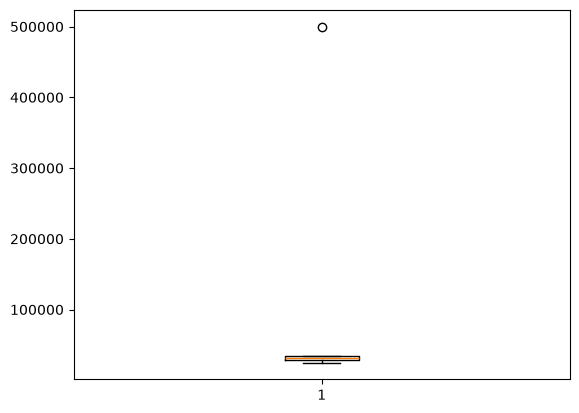

In [14]:
import matplotlib.pyplot as plt
plt.boxplot(df["Salary"])

In [19]:
#clip - it puts the values in between lower to lower bound values and upper to upper bound
df["Salary_Capped"] = df["Salary"].clip(
    lower=lower_bound,
    upper=Upper_bound
)
df["Salary_Capped"] 

0    25000
1    28000
2    30000
3    32000
4    35000
5    42875
Name: Salary_Capped, dtype: int64

# Lecture 86

In [20]:
marks = 90
std = 10
avg = 70
print("Z-score : " , (marks - avg)/std)

Z-score :  2.0


In [22]:
data = np.array([45, 48, 50, 52, 55, 58, 60, 100])
avg = np.mean(data)
std = np.std(data)
sc = (data - avg)/std#z_score
print(avg,std,sc)

58.5 16.3707055437449 [-0.82464375 -0.64138958 -0.51922014 -0.39705069 -0.21379653 -0.03054236
  0.09162708  2.53501597]


In [25]:
print("Outliers : ",data[(sc>3) | (sc < -3 )]) #range from this

Outliers :  []


In [26]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Salary": [
        48000, 50000, 51000, 49000, 52000,
        50000, 53000, 48000, 51000, 52000,
        49000, 50000, 51000, 52000, 48000,
        53000, 49000, 50000, 52000, 51000,
        150000
    ]
})
avg = df["Salary"].mean()
standard_Deviation = df["Salary"].std(ddof = 0)
z = (df["Salary"] - avg) / standard_Deviation
# df["Salary"] = df["Salary"] 
df[z >= 3]

,Salary
20,150000


In [27]:
print("Skewness:", df["Salary"].skew()) #tells the skewness of +ve side means the values are on +ve side is far from the normal

Skewness: 4.543405481615021


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Student": ["Rahul", "Priya", "Amit", "Sneha", "Karan",
                "Neha", "Rohan", "Pooja", "Arjun", "Meera"],
    "Marks": [45, 55, 60, 65, 70, 72, 75, 80, 85, 95],
    "City": ["Pune", "Mumbai", "Pune", "Nashik", "Mumbai",
             "Pune", "Nashik", "Mumbai", "Pune", "Nashik"]
})

print(df)

  Student  Marks    City
0   Rahul     45    Pune
1   Priya     55  Mumbai
2    Amit     60    Pune
3   Sneha     65  Nashik
4   Karan     70  Mumbai
5    Neha     72    Pune
6   Rohan     75  Nashik
7   Pooja     80  Mumbai
8   Arjun     85    Pune
9   Meera     95  Nashik


In [29]:
print(df["City"].value_counts())

City
Pune      4
Mumbai    3
Nashik    3
Name: count, dtype: int64


In [30]:
print(df["City"].value_counts(normalize=True))

City
Pune      0.4
Mumbai    0.3
Nashik    0.3
Name: proportion, dtype: float64


In [31]:
print(df["City"].value_counts(normalize=True)*100)#got the pecentage 

City
Pune      40.0
Mumbai    30.0
Nashik    30.0
Name: proportion, dtype: float64


In [32]:
print(df["City"].mode())

0    Pune
Name: City, dtype: str


In [33]:
print(df["City"].mode()[0])

Pune


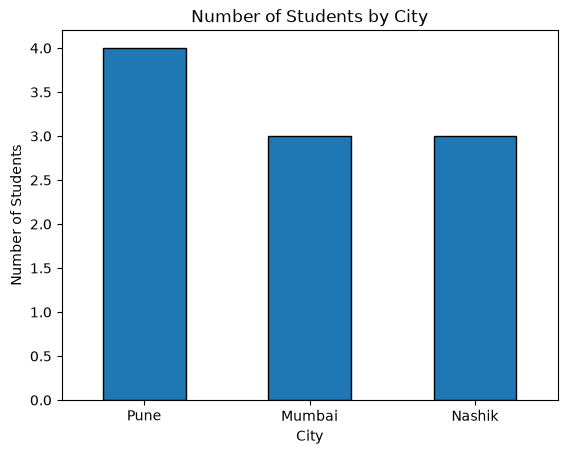

In [34]:
df["City"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Number of Students by City")
plt.xlabel("City")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

# Lecture 88

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.DataFrame({
    "Student": ["Rahul", "Priya", "Amit", "Sneha", "Karan",
                "Neha", "Rohan", "Pooja", "Arjun", "Meera"],
    "Study_Hours": [2, 5, 3, 7, 4, 6, 1, 8, 5, 3],
    "Marks": [45, 75, 55, 90, 65, 82, 35, 95, 78, 52],
    "City": ["Pune", "Mumbai", "Pune", "Nashik", "Mumbai",
             "Pune", "Nashik", "Mumbai", "Pune", "Nashik"],
    "Result": ["Fail", "Pass", "Fail", "Pass", "Pass",
               "Pass", "Fail", "Pass", "Pass", "Fail"]
})

print(df)

  Student  Study_Hours  Marks    City Result
0   Rahul            2     45    Pune   Fail
1   Priya            5     75  Mumbai   Pass
2    Amit            3     55    Pune   Fail
3   Sneha            7     90  Nashik   Pass
4   Karan            4     65  Mumbai   Pass
5    Neha            6     82    Pune   Pass
6   Rohan            1     35  Nashik   Fail
7   Pooja            8     95  Mumbai   Pass
8   Arjun            5     78    Pune   Pass
9   Meera            3     52  Nashik   Fail


Text(0, 0.5, 'Marks')

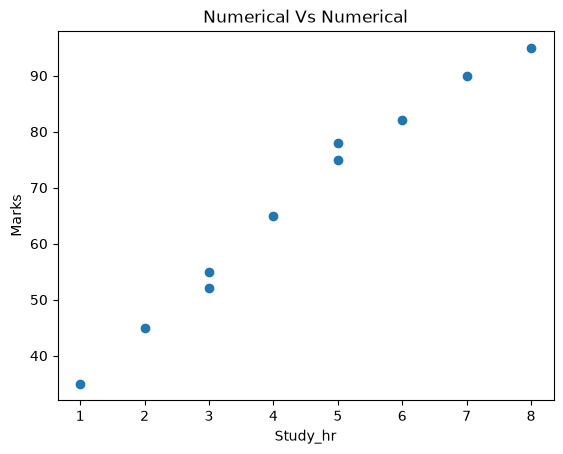

In [41]:
#numerical VS Numerical -- shown by scatter plot - correlation
plt.scatter(df["Study_Hours"],df["Marks"])
plt.title("Numerical Vs Numerical")
plt.xlabel("Study_hr")
plt.ylabel("Marks")

In [40]:
df["Study_Hours"].corr(df["Marks"])

np.float64(0.9905004952503718)

In [42]:
# Categorical vs Numerical Analysis
city_summary = df.groupby("City")["Marks"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(city_summary)

        count       mean  median  min  max
City                                      
Mumbai      3  78.333333    75.0   65   95
Nashik      3  59.000000    52.0   35   90
Pune        4  65.000000    66.5   45   82


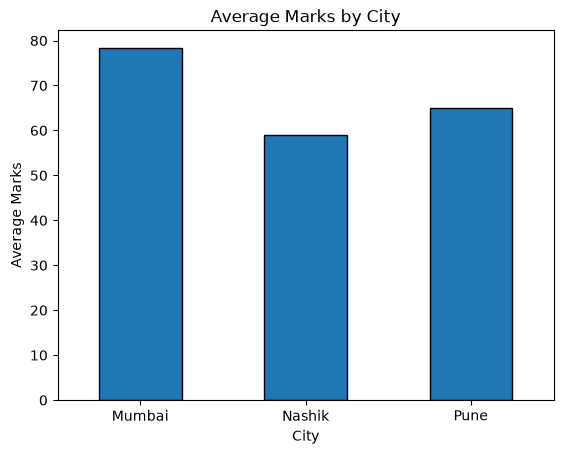

In [43]:
df.groupby("City")["Marks"].mean().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Marks by City")
plt.xlabel("City")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.show()

In [44]:
# Categorical vs Categorical Analysis -- crosstab used to show relationship
result_table = pd.crosstab(df["City"], df["Result"])

print(result_table)

Result  Fail  Pass
City              
Mumbai     0     3
Nashik     2     1
Pune       2     2


In [46]:
result_table = pd.crosstab(df["City"], df["Result"],normalize="index")*100

print(result_table)

Result       Fail        Pass
City                         
Mumbai   0.000000  100.000000
Nashik  66.666667   33.333333
Pune    50.000000   50.000000


# Lecture 89

In [47]:
df = pd.DataFrame({
    "Study_Hours": [2, 5, 3, 7, 4, 6, 1, 8, 5, 3],
    "Attendance": [60, 80, 65, 90, 75, 85, 50, 95, 88, 70],
    "Previous_Marks": [40, 65, 50, 80, 60, 75, 35, 85, 70, 48],
    "Final_Marks": [45, 75, 55, 90, 65, 82, 35, 95, 78, 52],
    "Result": [
        "Fail", "Pass", "Fail", "Pass", "Pass",
        "Pass", "Fail", "Pass", "Pass", "Fail"
    ]
})

print(df.head())

   Study_Hours  Attendance  Previous_Marks  Final_Marks Result
0            2          60              40           45   Fail
1            5          80              65           75   Pass
2            3          65              50           55   Fail
3            7          90              80           90   Pass
4            4          75              60           65   Pass


In [48]:
correlation = df[
    ["Study_Hours", "Attendance",
     "Previous_Marks", "Final_Marks"]
].corr()

print(correlation.round(2))

                Study_Hours  Attendance  Previous_Marks  Final_Marks
Study_Hours            1.00        0.97            0.99         0.99
Attendance             0.97        1.00            0.98         0.98
Previous_Marks         0.99        0.98            1.00         1.00
Final_Marks            0.99        0.98            1.00         1.00


<Axes: >

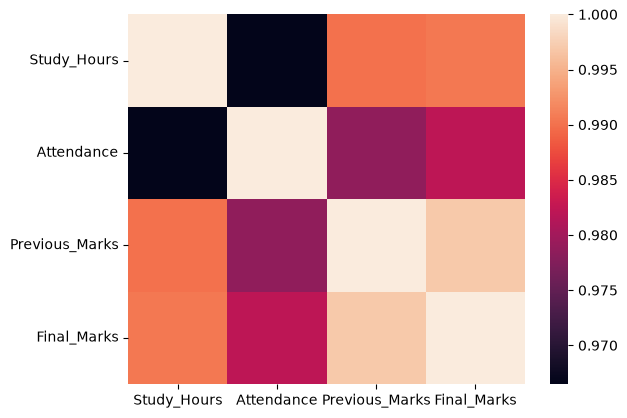

In [50]:
import seaborn as sns
sns.heatmap(correlation)

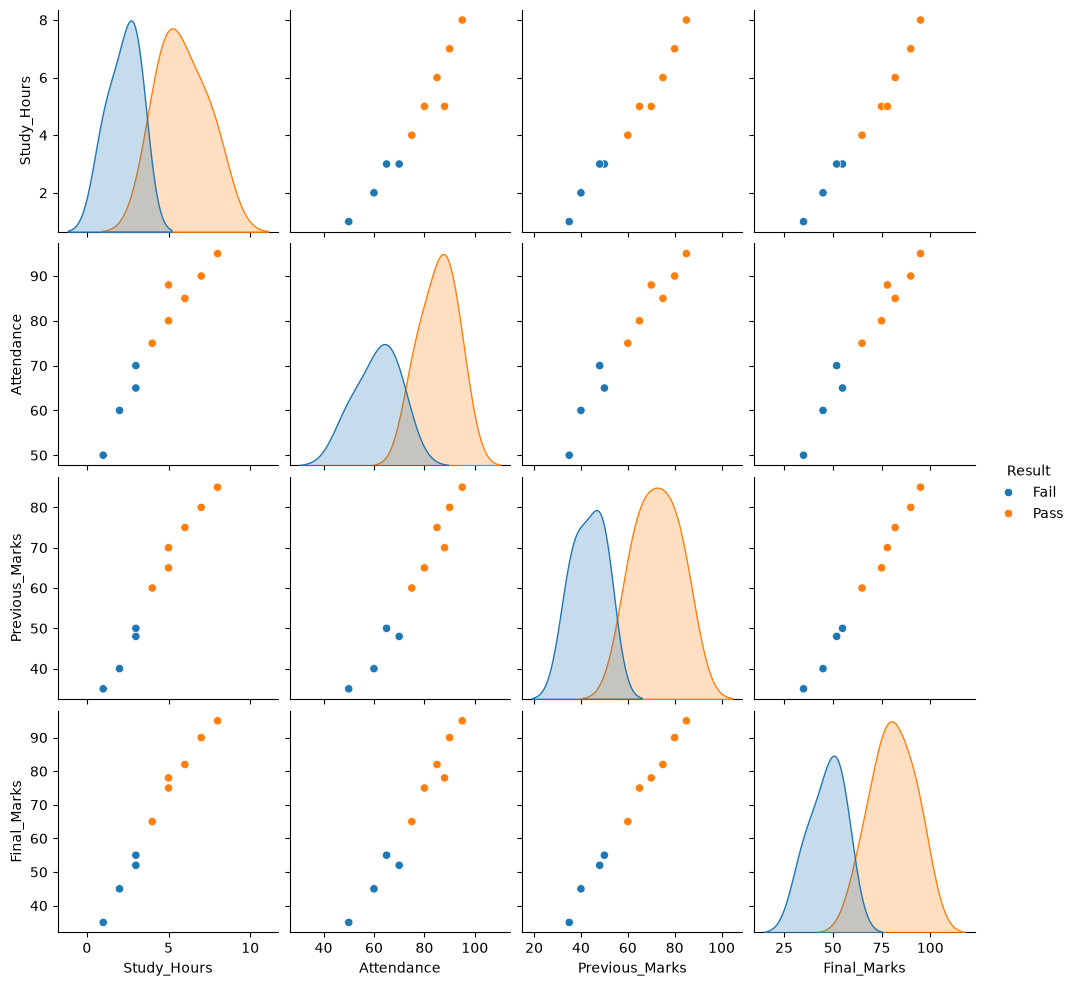

In [51]:
sns.pairplot(
    df,
    vars=[
        "Study_Hours",
        "Attendance",
        "Previous_Marks",
        "Final_Marks"
    ],
    hue="Result"
)

plt.show()

In [52]:
summary = df.groupby("Result")[
    ["Study_Hours", "Attendance",
     "Previous_Marks", "Final_Marks"]
].mean()

print(summary.round(2))

        Study_Hours  Attendance  Previous_Marks  Final_Marks
Result                                                      
Fail           2.25       61.25           43.25        46.75
Pass           5.83       85.50           72.50        80.83


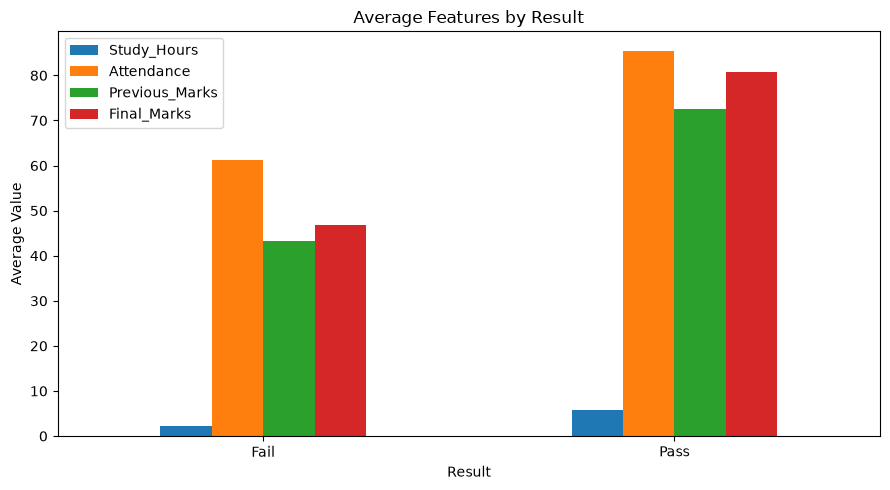

In [53]:
summary.plot(kind="bar", figsize=(9, 5))

plt.title("Average Features by Result")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Lecture 90

  Student  Study_Hours  Marks Department
0    Amit            2     45         IT
1   Priya            5     75         CS
2   Rahul            3     55         IT
3   Sneha            7     90         CS
4   Karan            4     65       ENTC
5    Neha            6     82         IT
6   Rohan            1     35       ENTC
7   Pooja            8     95         CS
8   Arjun            5     78         IT
9   Meera            3     52       ENTC


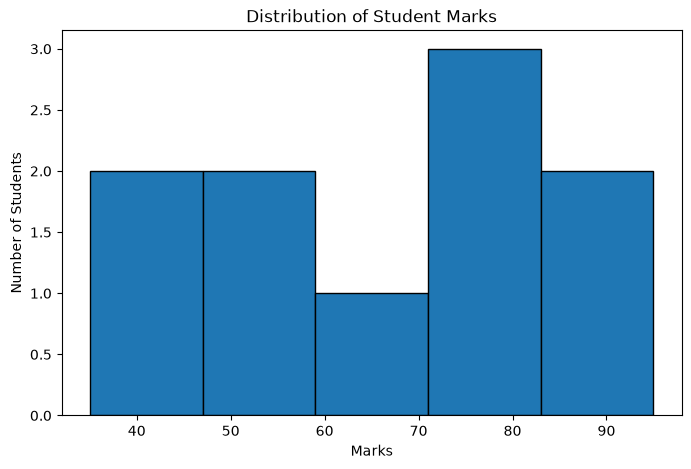

In [55]:
df = pd.DataFrame({
    "Student": [
        "Amit", "Priya", "Rahul", "Sneha", "Karan",
        "Neha", "Rohan", "Pooja", "Arjun", "Meera"
    ],
    "Study_Hours": [2, 5, 3, 7, 4, 6, 1, 8, 5, 3],
    "Marks": [45, 75, 55, 90, 65, 82, 35, 95, 78, 52],
    "Department": [
        "IT", "CS", "IT", "CS", "ENTC",
        "IT", "ENTC", "CS", "IT", "ENTC"
    ]
})

print(df)
plt.figure(figsize=(8, 5))

plt.hist(df["Marks"], bins=5, edgecolor="black")

plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")

plt.show()#show the values in v=bins by freq

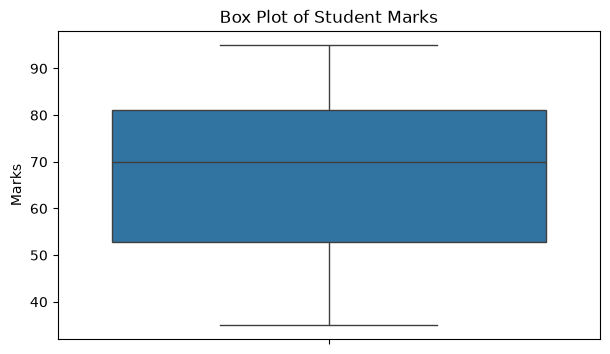

In [56]:
plt.figure(figsize=(7, 4))

sns.boxplot(y=df["Marks"])

plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")

plt.show()

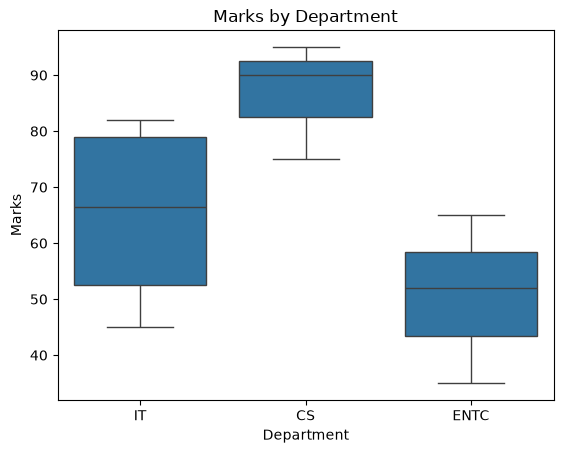

In [57]:
sns.boxplot(
    data=df,
    x="Department",
    y="Marks"
)

plt.title("Marks by Department")
plt.show()

# Lecture 91

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5],
    "Marks": [35, 45, 55, 65, 75],
    "Sleep_Hours": [8, 7, 7, 6, 6]
})

correlation = df["Study_Hours"].corr(df["Marks"])

print("Correlation:", correlation)

Correlation: 1.0


In [2]:
df["Study_Hours"].corr(df["Marks"], method="pearson")

np.float64(1.0)

In [4]:
df["Study_Hours"].cov(df["Marks"])

np.float64(25.0)

In [5]:
corr_matrix = df.corr(numeric_only=True)
round(corr_matrix,2)

,Study_Hours,Marks,Sleep_Hours
Study_Hours,1.00,1.00,-0.94
Marks,1.00,1.00,-0.94
Sleep_Hours,-0.94,-0.94,1.00


<Axes: >

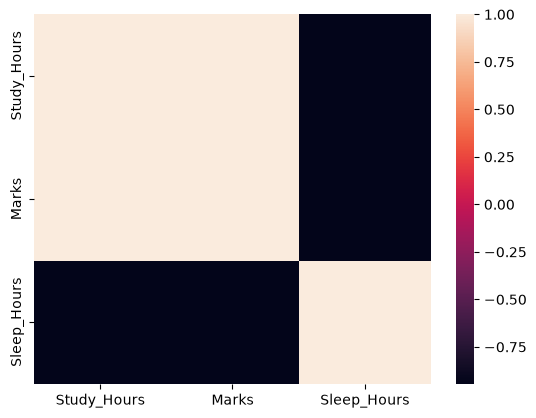

In [6]:
sns.heatmap(corr_matrix)

# Lecture 92

In [3]:
import pandas as pd
df_fraud = pd.DataFrame({
    "Amount": [100, 200, 150, 300, 500, 700, 120, 250],
    "Transaction_Type": [
        "Online", "Store", "Online", "Store",
        "Online", "Online", "Store", "Online"
    ],
    "Fraud": [
        "No", "No", "No", "No",
        "No", "Yes", "No", "No"
    ]
})#this couse the prediction always fraud data becoz the no is many times so we have to balance it

<Axes: xlabel='count', ylabel='Fraud'>

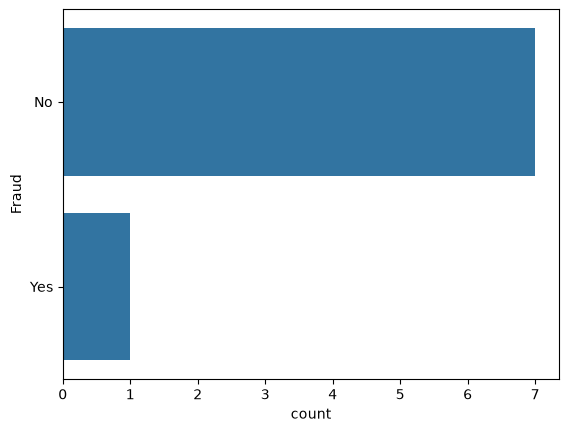

In [5]:
import seaborn as sns
sns.countplot(df_fraud["Fraud"])

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight="balanced")
df_fraud["Transaction_Type"] = df_fraud["Transaction_Type"].apply(lambda x: 1 if x == "Online" else 0)
x = df_fraud[["Amount","Transaction_Type"]]
y = df_fraud["Fraud"]
model.fit(x,y)
model.score(x,y)

1.0

In [18]:
model.predict([[700,1]])

C:\Users\Tejas Gaikwad\anaconda3\envs\datascience\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array(['Yes'], dtype=object)

In [19]:
model.predict([[750,1]])

C:\Users\Tejas Gaikwad\anaconda3\envs\datascience\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array(['Yes'], dtype=object)

In [20]:
model.predict([[1000,0]])

C:\Users\Tejas Gaikwad\anaconda3\envs\datascience\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array(['Yes'], dtype=object)

In [21]:
model.predict([[100,1]])

C:\Users\Tejas Gaikwad\anaconda3\envs\datascience\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array(['No'], dtype=object)

# lecture 93

In [24]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

df = pd.DataFrame({
    "Study_Hours": [5.0, 3.5, 6.0, 4.0, None, 7.5, 2.0, None, 8.0, 5.5],
    "Attendance": [85, 70, 90, 75, 80, None, 60, 88, None, 92],
    "Previous_Marks": [65, 50, 80, 55, 60, 90, 40, 70, 85, 75],
    "Result": ["Pass", "Fail", "Pass", "Fail", "Pass", "Pass", "Fail", "Pass", "Pass", "Pass"]
})

# Example: X contains only legitimate prediction-time features
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



# Lecture 94

In [25]:
import pandas as pd

df = pd.DataFrame({
    "Experience": [1, 3, 5, 2],
    "Education": ["Graduate", "Masters", "Masters", "Graduate"],
    "City": ["Pune", "Mumbai", "Delhi", "Pune"],
    "Salary": [25000, 45000, 70000, 30000]
})

print(df)

   Experience Education    City  Salary
0           1  Graduate    Pune   25000
1           3   Masters  Mumbai   45000
2           5   Masters   Delhi   70000
3           2  Graduate    Pune   30000


In [26]:
# Label encoding -- we gives the label 0 1 2 3 
# for ex. we gives the city label 0-pune 1-delhi 3-mumbai it say that mumbai > delhi >pune becoz model train like this numerical value that may predict wrong - we use one hot encoding for that
# for ex. we use thi slabel for Education by order like Graduates 0 after 1 masters it seems good - here we use label encoding

In [29]:
#one hot encoding
df_encoding = pd.get_dummies(data = df,columns=["City"],dtype=int)

In [31]:
df_encoding

,Experience,Education,Salary,City_Delhi,City_Mumbai,City_Pune
0,1,Graduate,25000,0,0,1
1,3,Masters,45000,0,1,0
2,5,Masters,70000,1,0,0
3,2,Graduate,30000,0,0,1


In [32]:
df_encoding["Education"] = df_encoding["Education"].apply(lambda x : 0 if x == "Graduate" else 1)

In [33]:
df_encoding

,Experience,Education,Salary,City_Delhi,City_Mumbai,City_Pune
0,1,0,25000,0,0,1
1,3,1,45000,0,1,0
2,5,1,70000,1,0,0
3,2,0,30000,0,0,1


In [34]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.DataFrame({
    "Age": [20, 30, 40, 50],
    "Salary": [20000, 40000, 60000, 80000]
})

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=df.columns
)

print(scaled_df.round(2))

    Age  Salary
0 -1.34   -1.34
1 -0.45   -0.45
2  0.45    0.45
3  1.34    1.34


In [35]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

df = pd.DataFrame({
    "Age": [20, 30, 40, 50]
})

scaler = MinMaxScaler()

df["Age_Scaled"] = scaler.fit_transform(
    df[["Age"]]
)

print(df.round(2))

   Age  Age_Scaled
0   20        0.00
1   30        0.33
2   40        0.67
3   50        1.00


In [37]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

scaled_values = scaler.fit_transform(
    df[["Age"]]
)

print(scaled_values)

[[-1.        ]
 [-0.33333333]
 [ 0.33333333]
 [ 1.        ]]


In [38]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

df = pd.DataFrame({
    "Age": [22, 35, 45, 28, 52, 31, 40, 25, 48, 33,
            29, 55, 37, 42, 26, 50, 34, 44, 23, 39],
    "Income": [25000, 50000, 80000, 35000, 90000,
               45000, 70000, 30000, 85000, 55000,
               40000, 95000, 60000, 75000, 32000,
               88000, 52000, 78000, 28000, 68000],
    "City": ["Pune", "Mumbai", "Delhi", "Pune", "Delhi",
             "Mumbai", "Pune", "Delhi", "Mumbai", "Pune",
             "Delhi", "Mumbai", "Pune", "Delhi", "Mumbai",
             "Pune", "Delhi", "Mumbai", "Pune", "Delhi"],
    "Smoker": ["No", "Yes", "No", "No", "Yes",
               "No", "Yes", "No", "Yes", "No",
               "No", "Yes", "No", "Yes", "No",
               "Yes", "No", "Yes", "No", "Yes"],
    "Purchased": [0, 1, 1, 0, 1, 0, 1, 0, 1, 1,
                  0, 1, 0, 1, 0, 1, 0, 1, 0, 1]
})

X = df.drop(columns=["Purchased"])
y = df["Purchased"]

numeric_features = ["Age", "Income"]
categorical_features = ["City", "Smoker"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression())
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual values:", y_test.tolist())
print("Predictions:", predictions.tolist())
print("Accuracy:", accuracy_score(y_test, predictions))

Actual values: [0, 0, 1, 1, 1]
Predictions: [0, 0, 1, 1, 1]
Accuracy: 1.0


# Final Project

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Age": [22, 25, 28, 30, 35, 40, 45, 50, 29, 32, 35, 25, 30],
    "Experience": [0, 2, 4, 6, 10, 15, 20, 25, 5, 7, 10, 2, 6],
    "Education": [
        "Graduate", "Graduate", "Masters", "Graduate",
        "Masters", "Masters", "PhD", "PhD",
        "Masters", "Graduate", "Masters", "Graduate", "Graduate"
    ],
    "Department": [
        "IT", "HR", "IT", "Finance", "IT", "Finance",
        "IT", "Finance", "HR", "IT", "Finance", "HR", "Finance"
    ],
    "Salary": [
        25000, 30000, 40000, 45000, 60000, 80000,
        100000, 120000, 42000, 50000, 65000, 32000, np.nan
    ]
})

print(df)

    Age  Experience Education Department    Salary
0    22           0  Graduate         IT   25000.0
1    25           2  Graduate         HR   30000.0
2    28           4   Masters         IT   40000.0
3    30           6  Graduate    Finance   45000.0
4    35          10   Masters         IT   60000.0
5    40          15   Masters    Finance   80000.0
6    45          20       PhD         IT  100000.0
7    50          25       PhD    Finance  120000.0
8    29           5   Masters         HR   42000.0
9    32           7  Graduate         IT   50000.0
10   35          10   Masters    Finance   65000.0
11   25           2  Graduate         HR   32000.0
12   30           6  Graduate    Finance       NaN


In [42]:
print("Shape:", df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nLast five rows:")
print(df.tail())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe(include="all"))

Shape: (13, 5)

First five rows:
   Age  Experience Education Department   Salary
0   22           0  Graduate         IT  25000.0
1   25           2  Graduate         HR  30000.0
2   28           4   Masters         IT  40000.0
3   30           6  Graduate    Finance  45000.0
4   35          10   Masters         IT  60000.0

Last five rows:
    Age  Experience Education Department   Salary
8    29           5   Masters         HR  42000.0
9    32           7  Graduate         IT  50000.0
10   35          10   Masters    Finance  65000.0
11   25           2  Graduate         HR  32000.0
12   30           6  Graduate    Finance      NaN

Data types:
Age             int64
Experience      int64
Education         str
Department        str
Salary        float64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         13 non-

In [43]:
print(df.isnull().sum())

Age           0
Experience    0
Education     0
Department    0
Salary        1
dtype: int64


In [44]:
missing_percent = (df.isnull().mean() * 100).round(2)

print(missing_percent)

Age           0.00
Experience    0.00
Education     0.00
Department    0.00
Salary        7.69
dtype: float64


In [45]:
df = df.dropna(subset=["Salary"]).copy()

print("Shape after removing missing target:", df.shape)
print(df.isnull().sum())

Shape after removing missing target: (12, 5)
Age           0
Experience    0
Education     0
Department    0
Salary        0
dtype: int64


In [46]:
df

,Age,Experience,Education,Department,Salary
0,22,0,Graduate,IT,25000.0
1,25,2,Graduate,HR,30000.0
2,28,4,Masters,IT,40000.0
3,30,6,Graduate,Finance,45000.0
4,35,10,Masters,IT,60000.0
5,40,15,Masters,Finance,80000.0
6,45,20,PhD,IT,100000.0
7,50,25,PhD,Finance,120000.0
8,29,5,Masters,HR,42000.0
9,32,7,Graduate,IT,50000.0


In [47]:
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


In [48]:
df

,Age,Experience,Education,Department,Salary
0,22,0,Graduate,IT,25000.0
1,25,2,Graduate,HR,30000.0
2,28,4,Masters,IT,40000.0
3,30,6,Graduate,Finance,45000.0
4,35,10,Masters,IT,60000.0
5,40,15,Masters,Finance,80000.0
6,45,20,PhD,IT,100000.0
7,50,25,PhD,Finance,120000.0
8,29,5,Masters,HR,42000.0
9,32,7,Graduate,IT,50000.0


In [49]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Shape after duplicate removal: (12, 5)
Duplicate rows remaining: 0


In [50]:
print("Negative ages:", (df["Age"] < 0).sum())
print("Negative experience:", (df["Experience"] < 0).sum())
print("Non-positive salaries:", (df["Salary"] <= 0).sum())

Negative ages: 0
Negative experience: 0
Non-positive salaries: 0


In [51]:
print(
    df[df["Experience"] > df["Age"]]
)

Empty DataFrame
Columns: [Age, Experience, Education, Department, Salary]
Index: []


In [52]:
print(df[["Age", "Experience", "Salary"]].describe())

             Age  Experience         Salary
count  12.000000   12.000000      12.000000
mean   33.000000    8.833333   57416.666667
std     8.474561    7.673251   29392.201604
min    22.000000    0.000000   25000.000000
25%    27.250000    3.500000   38000.000000
50%    31.000000    6.500000   47500.000000
75%    36.250000   11.250000   68750.000000
max    50.000000   25.000000  120000.000000


In [53]:
print("Average salary:", df["Salary"].mean())
print("Median salary:", df["Salary"].median())
print("Minimum salary:", df["Salary"].min())
print("Maximum salary:", df["Salary"].max())
print("Average experience:", df["Experience"].mean())

Average salary: 57416.666666666664
Median salary: 47500.0
Minimum salary: 25000.0
Maximum salary: 120000.0
Average experience: 8.833333333333334


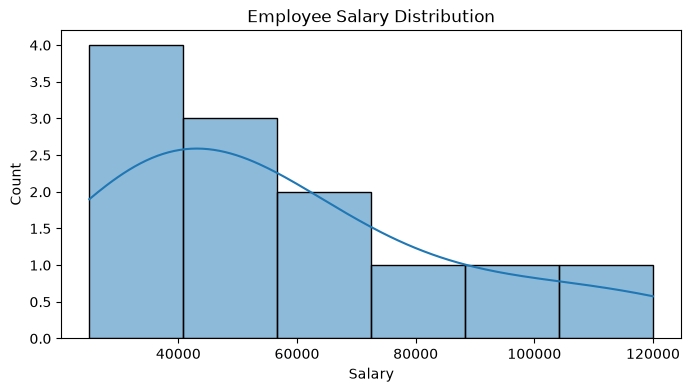

In [54]:
plt.figure(figsize=(8, 4))

sns.histplot(data=df, x="Salary", bins=6, kde=True)

plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Count")

plt.show()

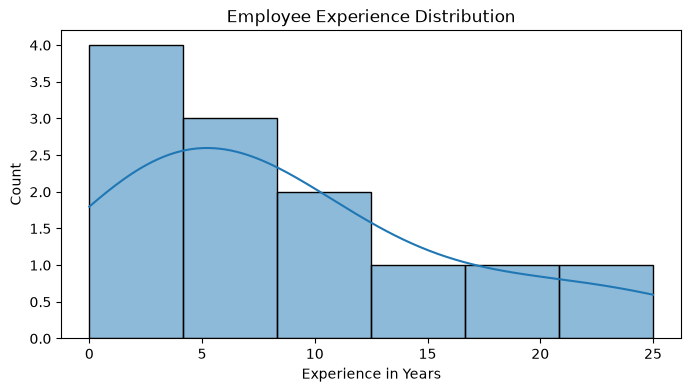

In [55]:
plt.figure(figsize=(8, 4))

sns.histplot(data=df, x="Experience", bins=6, kde=True)

plt.title("Employee Experience Distribution")
plt.xlabel("Experience in Years")

plt.show()

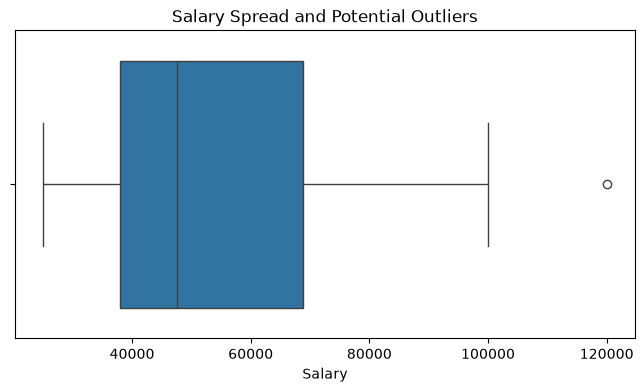

In [56]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="Salary")

plt.title("Salary Spread and Potential Outliers")

plt.show()

Department
IT         5
Finance    4
HR         3
Name: count, dtype: int64


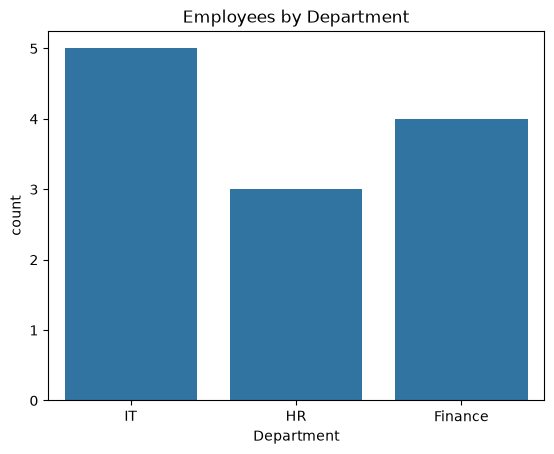

In [57]:
print(df["Department"].value_counts())

sns.countplot(data=df, x="Department")
plt.title("Employees by Department")
plt.show()

Education
Graduate    5
Masters     5
PhD         2
Name: count, dtype: int64


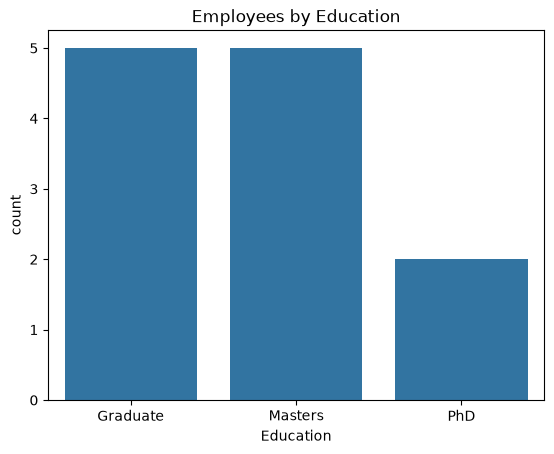

In [58]:
print(df["Education"].value_counts())

sns.countplot(data=df, x="Education")
plt.title("Employees by Education")
plt.show()

             Age  Experience  Salary
Age         1.00         1.0    0.99
Experience  1.00         1.0    1.00
Salary      0.99         1.0    1.00


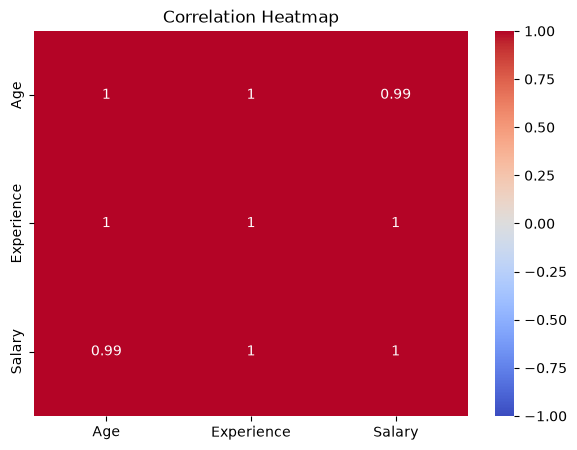

In [59]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

print(correlation.round(2))

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.show()

In [60]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Salary"] < lower_bound) |
    (df["Salary"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:")
print(outliers)

Lower bound: -8125.0
Upper bound: 114875.0
Potential outliers:
   Age  Experience Education Department    Salary
7   50          25       PhD    Finance  120000.0


In [61]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

X = df.drop(columns=["Salary"])
y = df["Salary"]

numeric_features = ["Age", "Experience"]
categorical_features = ["Education", "Department"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual salaries:", y_test.tolist())
print("Predicted salaries:", predictions.round(2).tolist())

print(
    "MAE:",
    round(mean_absolute_error(y_test, predictions), 2)
)

print(
    "R2 score:",
    round(r2_score(y_test, predictions), 2)
)

Actual salaries: [65000.0, 50000.0, 25000.0]
Predicted salaries: [60000.0, 45000.0, 29000.0]
MAE: 4666.67
R2 score: 0.92
